<a href="https://colab.research.google.com/github/100522142/Practica-Aprendizaje/blob/main/NoteBook1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Alumnos: Daniel Sánchez Piqueras (100526354), Miguel Trimiño Girón (100522142)

# **PRIMERA PRÁCTICA: PREDICCIÓN DE SUBSCRIPCIÓN A UN PRODUCTO BANCARIO**

## 2. EDA Simplificado

Primero de todo sacamos el dataset del archivo bank_09.pkl, en la variable x guardaremos los atributos x característicos y en la variable y la variable objetivo deposit.
Observaremos una tabla con unas cuantas instancias del dataset, el número de instancias y variables, una tabla de las variables continuas y el tipo del array formado por todas las columnas.

In [40]:
# Aqui importamos librerias
import pandas as pd
import numpy as np
import io
from IPython.display import display

# Cargamos el dataset desde un archivo y separamos en variables predictoras (x) y objetivo (y)
datos = pd.read_pickle('bank_09.pkl')
x = datos.iloc[:, :-1]
y = datos.iloc[:, -1]

# Identificamos las columnas que actúan como identificadores únicos, osea que todos sus valores son distintos
posibles_ids = [col for col in x.columns if x[col].nunique() == len(x)]

# Para visualizar la tabla, la dimensión y un resumen estadístico
print("Resumen del dataset:")
display(datos)
print("(Número de instancias, Número de variables características): ")
print(x.shape)
print("(Número de instancias, Número de variables respuesta): ")
print(y.shape)
display(datos.describe())

# Convertimos las variables predictoras a una matriz de numpy
array = np.array(x)
print(array.dtype)

Resumen del dataset:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,no


(Número de instancias, Número de variables características): 
(11000, 16)
(Número de instancias, Número de variables respuesta): 
(11000,)


,age,balance,day,duration,campaign,pdays,previous
count,11000.000000,11000.000000,11000.000000,11000.000000,11000.00000,11000.000000,11000.000000
mean,41.252727,1529.139273,15.660818,372.524909,2.50800,51.308636,0.828000
std,11.940474,3217.396248,8.417970,347.515713,2.72221,108.782842,2.282936
min,18.000000,-6847.000000,1.000000,2.000000,1.00000,-1.000000,0.000000
25%,32.000000,122.750000,8.000000,138.000000,1.00000,-1.000000,0.000000
50%,39.000000,549.500000,15.000000,255.000000,2.00000,-1.000000,0.000000
75%,49.000000,1711.000000,22.000000,498.000000,3.00000,20.250000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.00000,854.000000,58.000000


object


Podemos observar que existe 16 variables de características y una variable de respuesta, formando 17 variables del dataset. Además, se detectan 11000 instancias.

Las variables age, balance, day, duration, campaign, pdays, previous son variables numéricas mientras que el resto son categóricas.

# Comprobamos las variables categóricas con alta cardinalidad (>10 valores únicos)

In [41]:
# Las columnas categóricas con alta cardinalidad, osea las que tienes mas de 10 valores únicos
columnas_categoricas = x.select_dtypes(include=['object']).columns
cardinalidad = x[columnas_categoricas].nunique()
alta_cardinalidad = cardinalidad[cardinalidad > 10]

# Aqui solo comprobamos los resultados y vemos las columnas problemáticas (si las hay claro)
print("Variables con alta cardinalidad (>10 valores únicos):")
if alta_cardinalidad.empty:
    print("Ninguna columna supera los 10 valores únicos.")
else:
    print(alta_cardinalidad)

Variables con alta cardinalidad (>10 valores únicos):
job      12
month    12
dtype: int64


Podemos observar que las variables month y job son de alta cardinalidad. En el preprocesado se manejarán estas dos variables con OneHotEncoder(), creando variables dummy, ya que añadir 12 columnas más no aumenta excesivamente la dimensionalidad.

# Buscamos qué variables tienen valores faltantes y cuantos

In [42]:
# Aqui vemos las columnas que tienen al menos un valor nulo para que no afecte a nuestro dataset
columnas_con_nulos = x.columns[x.isnull().any()]
print("Columnas que contienen al menos un valor nulo:")
print(columnas_con_nulos)

# Contamos los valores nulos por columnas para tener mas o menos idea del tamaño del problema de los nulos
print("\nTotal de nulos por columna:")
print(x.isnull().sum())

# Aqui extraemos y vemos las flias que tienen valores Nan
filas_con_nan = x[x.isna().any(axis=1)]
print(f"Hay {len(filas_con_nan)} filas con verdaderos NaN.")
display(filas_con_nan.head(10))

Columnas que contienen al menos un valor nulo:
Index(['job', 'marital'], dtype='object')

Total de nulos por columna:
age            0
job           97
marital      282
education      0
default        0
balance        0
housing        0
loan           0
contact        0
day            0
month          0
duration       0
campaign       0
pdays          0
previous       0
poutcome       0
dtype: int64
Hay 376 filas con verdaderos NaN.


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
7,60,None,divorced,secondary,no,545,yes,no,unknown,6,may,1030,1,-1,0,unknown
31,60,technician,None,primary,no,65,yes,no,unknown,9,may,1028,2,-1,0,unknown
44,52,None,married,unknown,no,2240,yes,no,unknown,13,may,845,1,-1,0,unknown
52,59,retired,None,secondary,no,1521,yes,yes,unknown,14,may,1125,2,-1,0,unknown
60,51,blue-collar,None,secondary,no,7180,yes,no,unknown,14,may,927,1,-1,0,unknown
115,37,technician,None,secondary,no,1211,yes,no,unknown,21,may,795,1,-1,0,unknown
116,36,blue-collar,None,primary,no,599,yes,no,unknown,21,may,649,2,-1,0,unknown
154,29,management,None,tertiary,no,314,no,no,unknown,28,may,938,2,-1,0,unknown
175,30,None,married,secondary,no,486,yes,no,unknown,29,may,1109,3,-1,0,unknown
182,38,admin.,None,secondary,no,19,yes,no,unknown,30,may,604,2,-1,0,unknown


Podemos observar que las variables job y martial tienen 97 y 282 valores Nan respectivamente. En el preprocesado se rellenarán esos espacios vacios utilizando la técnica del valor más frecuente (Moda).

# Buscamos las variables que puedan ser ids

In [43]:
# Aqui buscamos las columnas identificadoras, basicamente las que tienen un valor único por fila
posibles_ids = [col for col in x.columns if x[col].nunique() == len(x)]

# Comprobamos y printeamos las columnas que nos parecen ID´s
if len(posibles_ids) > 0:
    print("Columnas que parecen ser IDs:", posibles_ids)
else:
    print("No se encontraron columnas que parecen ser IDs.")

No se encontraron columnas que parecen ser IDs.


Podemos observar que no existen variables en x cuyos valores sean únicos

# Buscamos variables de valor único, es decir, variables constantes

In [44]:
# Vemos que columnas tienen un solo valor único, que son constantes vaya. Estas no tienen poder predictivo por tener un solo valor
columnas_constantes = [col for col in x.columns if x[col].nunique() <= 1]

# Como antes, comprobamos y printeamos las columnas que son constantes
if len(columnas_constantes) > 0:
    print("Columnas constantes encontradas:", columnas_constantes)
else:
    print("No se encontraron columnas constantes.")

No se encontraron columnas constantes.


Podemos observar que no existen variables en x cuyos valores sean contantes, es decir, iguales.

Al no detectarse variables ids ni variables constantes no, podemos eliminar ninguna columna. Si hubieramos encontrado, se eliminarian las posibles columnas id por overfitting y las columnas constantes por falta de variabilidad.

# Detectamos los outliers

In [45]:
# Usamos esto para contar colecciones
from collections import Counter 

# Con esta función detectamos los outliners multivariables para usando el metodo del rango intercuartil (IQR)
def detect_outliers(df,features):
    outlier_indices = [] 
    """
    Detecta índices de filas que son outliers en múltiples columnas.

    Parámetros
    ----------
    df       : DataFrame con los datos.
    features : Lista de nombres de columnas numéricas a analizar.

    Retorna
    -------
    multiple_outliers : Lista de índices de filas que son outliers
                        en más de 2 de las columnas indicadas.
    """
    
    # Calculamos los cuartiles y umbrales con el metodo Tukey y cogemos los indices atípicos para cada característica
    for c in features:
        Q1 = np.percentile(df[c],25)
        Q3 = np.percentile(df[c],75)
        IQR = Q3 - Q1
        outlier_step = IQR * 1.5
        
        outlier_list_col = df[
            (df[c] < Q1 - outlier_step) | 
            (df[c] > Q3 + outlier_step)].index 
        
        outlier_indices.extend(outlier_list_col)

    # Contamos las repeticiones y filtramos por los que aparcen más de 2 veces en columnas diferentes
    outlier_indices = Counter(outlier_indices)
    multiple_outliers = list(i for i, v in outlier_indices.items() if v > 2)

    return multiple_outliers


# Mostramos la tabla con las filas con valores de atributos outliers

In [46]:
# Nuestra ejecución de la detección de outliers sobre las columnas numéricas (el método IQR no aplica a categóricas):
outliers_detectados = detect_outliers(x, [
    "age", "balance", "day", "duration", "campaign", "pdays", "previous"
])

# Aqui filtramos y visualizamos las filas completas que han sido identificadas como atípicas
x.loc[outliers_detectados]

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
2665,79,retired,married,secondary,no,723,no,no,telephone,9,sep,276,1,79,3,failure
2778,76,housemaid,divorced,primary,no,1411,no,no,telephone,19,oct,233,2,187,3,success
2809,82,retired,married,primary,no,8603,no,no,cellular,22,oct,306,3,107,1,success
2820,77,management,married,unknown,no,1780,yes,no,cellular,23,oct,221,2,183,3,success
2931,76,retired,married,primary,no,3324,no,no,cellular,13,nov,122,1,92,3,success
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9214,57,services,married,secondary,no,0,yes,no,cellular,14,may,16,9,282,3,other
10157,44,management,married,tertiary,no,1451,yes,no,cellular,5,feb,80,7,80,15,failure
10573,44,admin.,single,secondary,no,985,yes,yes,cellular,11,may,9,7,325,19,failure
10765,37,management,married,tertiary,no,26,no,no,cellular,17,jun,151,7,62,4,failure


# Tabla comparación media de age y balance de las instancias con valor Outlier

In [47]:
# Tenemos que etiquetar todas las filas y sobrescribir aquellas que hemos identificado como outliers
x['tipo_dato'] = 'Normal'
lista_outliers = detect_outliers(x, ["age", "balance", "day", "duration", "campaign", "pdays", "previous"])
x.loc[lista_outliers, 'tipo_dato'] = 'Outlier'

# Aqui cambiamos la variable objetivo (de 'yes'/'no' a 1/0) para que el cálculo de proporciones (tasa de éxito) sea mas fácil
x['exito_num'] = y.map({'yes': 1, 'no': 0})

# Agrupamos por tipo de fila y cálculamos las medias para evaluar si los outliers tiene un sesgo en la conversión
comparacion = x.groupby('tipo_dato')[["age", "balance", "day", "duration", "campaign", "pdays", "previous", 'exito_num']].mean()
print(comparacion)

                 age      balance        day    duration  campaign  \
tipo_dato                                                            
Normal     41.103979  1427.189315  15.666265  368.548558  2.503200   
Outlier    48.575342  6547.963470  15.392694  568.273973  2.744292   

                pdays  previous  exito_num  
tipo_dato                                   
Normal      48.605139  0.727298   0.468324  
Outlier    184.397260  5.785388   0.780822  


La media de los datos de age normales y la media de los datos de age atípicos es un número similar. Por el contrario, la media de los datos de age normales y la media de los datos de age atípicos es muy distinto, indicando que los clientes atipicos tienen mayor balance. Previous, pdays y duration.
Podemos observar que los clientes outliers son los que tienen más probabilidad de realizar un deposito teniendo un 78% de exito frente al 46% de exito de los clientes normales.

# Buscamos la correlación entre las variables

# Correlación entre las variables númericas

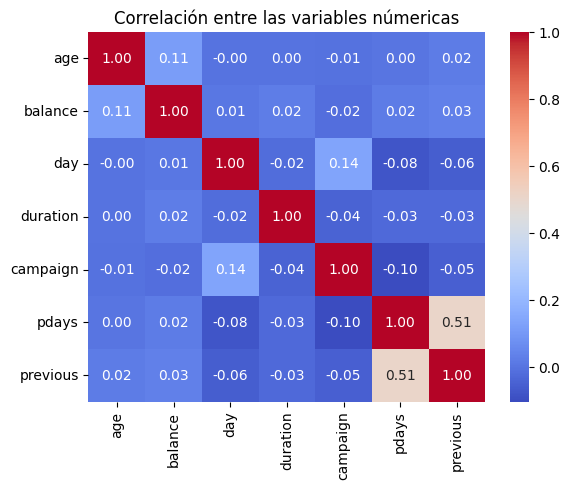

In [48]:
# Tenemos que importar las librerías de las gráficas y también seleccionamos las columnas numéricas
import seaborn as sns
import matplotlib.pyplot as plt
list1 = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]

# Después, cálculamso la matriz de correlación de Pearson y hemos decicido hacerlo en un mapa de calor para identificar alguna posible multicolinealidad
sns.heatmap(x[list1].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlación entre las variables númericas")
plt.show()

Es relevante resaltar el valor de correlación entre pdays y previous (0.51), que aunque no sea lo suficientemente alto para eliminar una de las dos variables, es para notar que ambas comparten información sobre la historia de contacto del cliente.

# Tablas relacionando variables

# Tabla relación trabajo-deposito. En base al tipo de trabajo, ver cual es más probable que haga un depósito

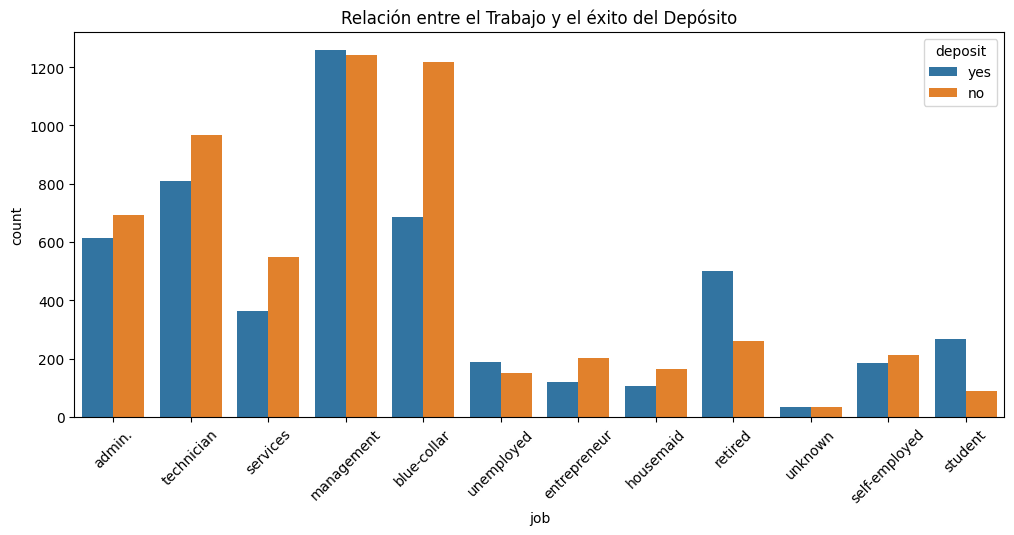

In [49]:
import seaborn as sns
import matplotlib.pyplot as plt

# Esta es la configuración de la gráfica y también generamos un gráfico de barras para analizar la relación entre la profesión y el éxito de la campaña
plt.figure(figsize=(12, 5))
sns.countplot(x='job', hue='deposit', data=datos)
plt.title('Relación entre el Trabajo y el éxito del Depósito')
plt.xticks(rotation=45)
plt.show()

Tras realizar el análisis bivariante entre la variable job y la variable objetivo deposit, podemos observar que en la mayor parte de trabajos, el exito y fracaso del deposito están igualados. Aún así, vemos que los jubilados y los estudiantes tienen mayor tasa de exito de deposito, siendo más atractivos para la campaña. Por el contrario, el trabajo blue-collar, a pesar de ser muy numeroso, presenta una alta tasa de rechazo. Estos hallazgos justifican la importancia de incluir el trabajo como una variable predictora clave en nuestro modelo.

Management es el grupo con más instancias, pero están muy divididos. Esto obligará al modelo a usar el balance para decidir en ese grupo.

# Tabla relacion poutcome-deposit. Comprobar si el cliente, al haber hecho un deposito con éxito anteriormente, es más probable que ahora diga sí también.

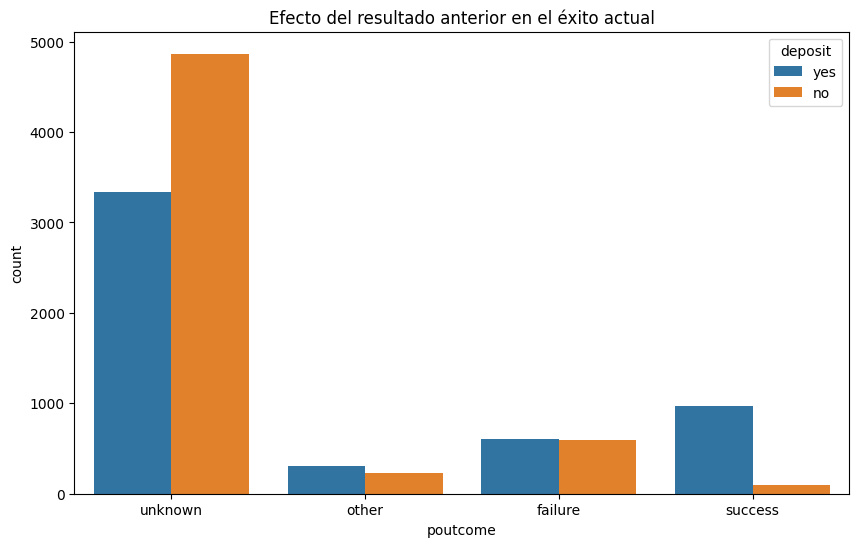

In [50]:
# Otra configuración de la gráfica y generamos un gráfico de barras para analizar el impacto del resultado de la campaña anterior en la conversión actual
plt.figure(figsize=(10,6))
sns.countplot(data=datos, x='poutcome', hue='deposit')
plt.title("Efecto del resultado anterior en el éxito actual")
plt.show()

Claramente observamos que se cumple. Si el cliente ya completó un deposito con exito, es bastante probable que lo vuelva a hacer.

# Tabla relación month-deposit. Comprobamos cual es el mes de mayor exito de depositos, y los meses donde la gente más ahorra.

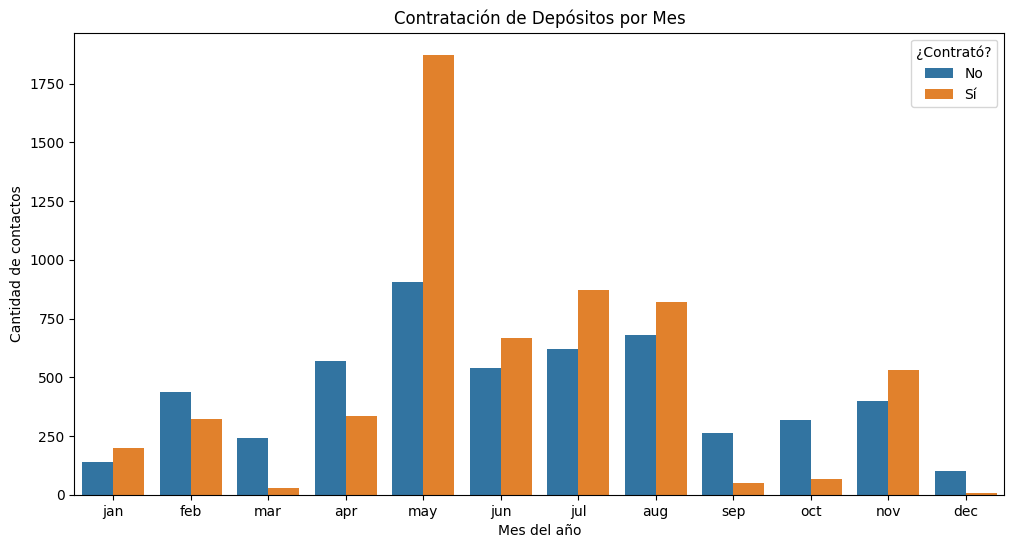

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt

# meses_ordenados simplemente es el orden cronológico y el resto es lageneración de un gráfico de barras para visualizar las contrataciones por mes
meses_ordenados = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
plt.figure(figsize=(12, 6))
sns.countplot(data=datos, x='month', hue='deposit', order=meses_ordenados)
plt.title('Contratación de Depósitos por Mes')
plt.xlabel('Mes del año')
plt.ylabel('Cantidad de contactos')
plt.legend(title='¿Contrató?', labels=['No', 'Sí'])
plt.show()

En mayo podemos observar muchos contactos, pero muchos fracasos. En marzo, abril, septiembre, octubre y diciembre hay menos contactos, pero bastante exito. Son meses donde la gente está muy receptiva.

# Tabla relación balance-deposito. Comprobamos si los clientes con más dinero en la cuenta son más propensos a decir que sí

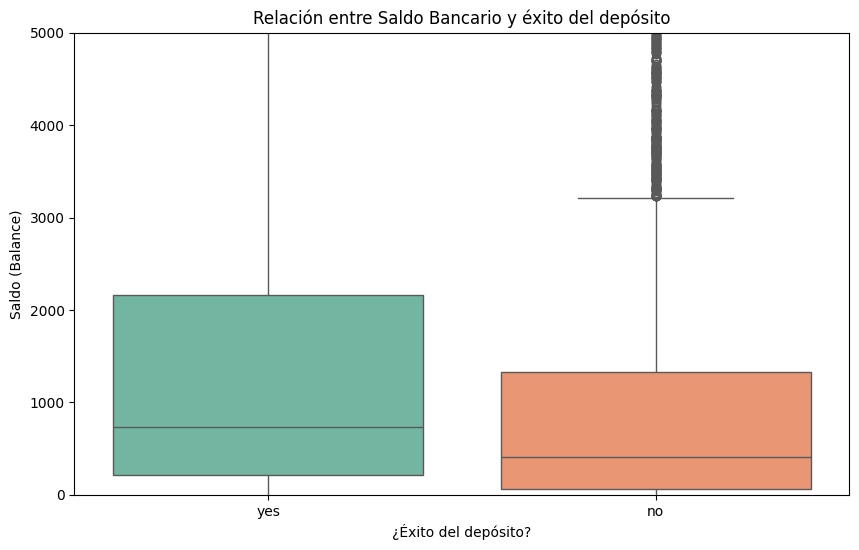

In [52]:
# De nuevo, otra configuración y otra generación de un diagrama de caja con límite en el eje Y para analizar la distribución del saldo según el éxito de la campaña
plt.figure(figsize=(10, 6))
sns.boxplot(data=datos, x='deposit', y='balance', hue='deposit', palette="Set2", legend=False)
plt.ylim(0, 5000)
plt.title('Relación entre Saldo Bancario y éxito del depósito')
plt.xlabel('¿Éxito del depósito?')
plt.ylabel('Saldo (Balance)')
plt.show()

Podemos observar que la gente con menos balance suele decir que no al deposito, mientras que la gente con un balance mayor es más probable que diga que sí. Observamos también un gran número de valores atípicos del balance de los clientes que rechazan el deposito, esto justificará el uso de RobustScaler en el Train.

# Análisis especial de la variable pdays y tipo de problema

Hacemos binaria la variable pdays, ya que valoramos más el si el cliente ha sido contactado o no a el número de dias que ha pasado desde que el cliente fue contactado para el exito del deposito

In [53]:
# Hacemos un análisis especial de la variable 'pdays' (días desde el último contacto): Decidimos hacer un cálculo de
# proporciones entre clientes nuevos (-1) y previamente contactados, y lso print es para ver sus estadísticas
total = len(x)
no_contactados = (x['pdays'] == -1).sum()
contactados    = (x['pdays'] >= 0).sum()

print("=== Análisis de pdays ===")
print(f"Valores -1 (sin contacto previo): {no_contactados} ({no_contactados/total*100:.1f}%)")
print(f"Valores >= 0 (con contacto previo): {contactados}  ({contactados/total*100:.1f}%)")
print()
print("Estadísticos (solo instancias con pdays >= 0):")
print(x.loc[x['pdays'] >= 0, 'pdays'].describe())

=== Análisis de pdays ===
Valores -1 (sin contacto previo): 8203 (74.6%)
Valores >= 0 (con contacto previo): 2797  (25.4%)

Estadísticos (solo instancias con pdays >= 0):
count    2797.000000
mean      204.718627
std       122.397953
min         1.000000
25%        98.000000
50%       182.000000
75%       286.000000
max       854.000000
Name: pdays, dtype: float64


El 74.6% de los clientes tienen pdays = -1, lo que significa que nunca fueron contactados
en una campaña anterior. Tratar ese -1 como un valor numérico más distorsionaría cualquier modelo
sensible a la escala (KNN, SVM, regresión logística).

# Estrategia de preprocesado para pdays:

1. Crear una variable binaria contactado_antes (1 si pdays != -1, 0 en caso contrario) que capture si el cliente tiene historial de campañas previas.
2. Reemplazar los -1 por 0 en pdays para que el escalado no se vea distorsionado (el -1 quedaría muy lejos del resto de valores reales).

In [54]:
# Seguimos con la variable pdays: Lo transformamos creaando un indicador binario de contacto previo y ajustamos el valor -1 a 0
# para la compatibilidad con los escaladores
x['contactado_antes'] = (x['pdays'] != -1).astype(int)
x['pdays'] = x['pdays'].replace(-1, 0)

# Sirve para printear la nueva distribución y las estadísticas actualizadas (de pdays claro)
print("Nueva distribución de contactado_antes:")
print(x['contactado_antes'].value_counts())
print()
print("Resumen de pdays tras la transformación:")
print(x['pdays'].describe())

Nueva distribución de contactado_antes:
contactado_antes
0    8203
1    2797
Name: count, dtype: int64

Resumen de pdays tras la transformación:
count    11000.000000
mean        52.054364
std        108.424506
min          0.000000
25%          0.000000
50%          0.000000
75%         20.250000
max        854.000000
Name: pdays, dtype: float64


Tipo de problema
Valores únicos de y: ['yes' 'no']
Dtype de y: object
Problema de CLASIFICACIÓN BINARIA (yes/no)

Balance de clases
deposit
no     5780
yes    5220
Name: count, dtype: int64
Ratio minoritaria/mayoritaria: 0.903
Clases prácticamente balanceadas (ratio ≥ 0.80). No es necesario oversampling.


Text(0, 0.5, 'Número de instancias')

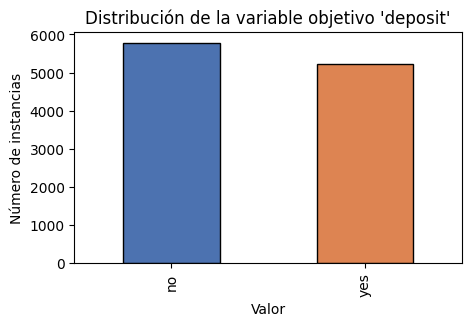

In [55]:
import matplotlib.pyplot as plt

# Esta es nuestra inspección de la variable objetivo (es una clasificación binaria) y además calculamos las proporciones entre clases
print("Tipo de problema")
print(f"Valores únicos de y: {y.unique()}")
print(f"Dtype de y: {y.dtype}")
print("Problema de CLASIFICACIÓN BINARIA (yes/no)")
print()
vc = y.value_counts()
ratio = vc.min() / vc.max()

# Tenemos que evaluar el ratio de clases para decidir si aplicar o no técnicas de remuestreo
print("Balance de clases")
print(vc)
print(f"Ratio minoritaria/mayoritaria: {ratio:.3f}")
if ratio >= 0.80:
    print("Clases prácticamente balanceadas (ratio ≥ 0.80). No es necesario oversampling.")
else:
    print("Clases desbalanceadas. Considerar técnicas de resampling.")

# Esta es la parte del grafo para ver la distribución de la variable objetivo
fig, ax = plt.subplots(figsize=(5, 3))
vc.plot(kind='bar', ax=ax, color=['#4c72b0', '#dd8452'], edgecolor='black')
ax.set_title("Distribución de la variable objetivo 'deposit'")
ax.set_xlabel("Valor")
ax.set_ylabel("Número de instancias")

Las clases están prácticamente balanceadas (ratio ≈ 0.90), por lo que no es necesario
aplicar técnicas de resampling. Se usará ROC-AUC como métrica principal a lo largo de
la práctica por las siguientes razones:
- Es robusta ante pequeños desbalances de clases.
- Mide la capacidad discriminativa del modelo independientemente del umbral de decisión.
- Permite comparar fácilmente distintos modelos.

---
# 3. Planteamiento de la Evaluación
## 3.1 Dividimos el Dataset en parte de train y parte de test

In [56]:
from sklearn.model_selection import train_test_split

# Esot es importante: Aquí dividimos el dataset en conjuntos de entrenamiento (67%) y prueba (33%) 
# para ello utilizamos una semilla fija para asegurar la reproducibilidad sin fugas de datos
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.33,
    random_state=54
)

# Priinteamos para verificar la cantidad de filas asignadas a cada subconjunto tras la partición
print(f"Tamaño entrenamiento: {x_train.shape[0]} filas")
print(f"Tamaño prueba:        {x_test.shape[0]} filas")

Tamaño entrenamiento: 7370 filas
Tamaño prueba:        3630 filas


Como hemos dicho antes se utilizará a lo largo de esta práctica la métrica ROC-AUC, ya que es robusta ante pequeños desbalanceos de clases y permite comparar fácilmente distintos modelos.

## 3.3 Decide cómo se va a llevar a cabo la evaluación interna (inner)

Esta fase constituye el núcleo de la experimentación. Se lleva a cabo integramente sobre el conjunto de entrenamiento utilizando Validación Cruzada con 3 K-folds. Su propósito es doble:

- Optimización de Hiperparámetros (HPO): Permite al GridSearchCV probar múltiples combinaciones de parámetros y seleccionar la mejor basándose en la media del ROC-AUC de los diferentes folds.

- Comparación de Modelos: Al utilizar la misma partición interna para KNN, árboles de decisión, Regresión Logística y SVM, podemos comparar su rendimiento en base a la media ROC-AUC y tiempo de entrenamiento. El modelo que obtenga la mejor métrica media en esta fase será nuestro modelo final.


# 4. Métodos Básicos: KNN y Árboles de Decisión

# 4.1 Preprocesado KNN

# En el proprocesado, creamos las variables dummies para las variables de más de 2 valores de cardinalidad, rellenamos los valores faltantes de las columnas job y marital, y probamos MinMaxScaler

Creamos tres pipelines especializados: uno para las variables numéricas donde aplicamos el escalado, otro para un grupo de variables categóricas donde realizamos una limpieza previa de nulos y la imputación de la moda, y un tercero para el resto de categóricas que pasan directamente a la creación de dummies. Finalmente, para unir estos procesos creamos el ColumnTransformer, que ejecutará los tres pipelines de forma independiente y los concatenará en una única matriz numérica lista para el modelo.

In [57]:
# Usamos Pipeline + ColumnTransformer de scikit-learn para encadenar
# transformaciones de forma limpia y evitar data leakage:
#   -Los parámetros de imputación y escalado se aprenden SOLO con train.
#   -Se aplican (transform) sobre train y test sin reentrenarse.
from sklearn.impute import SimpleImputer # Imputación de valores faltantes
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer # Codificación y escalado
from sklearn.compose import ColumnTransformer # Aplica transformaciones por tipo de columna
from sklearn.pipeline import Pipeline # Encadena pasos de transformación

# Definición de columnas por tipo
# Columnas que contienen texto/categorías → requieren codificación dummy
cols_categoricas = [
    'education',  # Nivel educativo
    'default',    # ¿Tiene crédito en impago?
    'housing',    # ¿Tiene hipoteca?
    'loan',       # ¿Tiene préstamo personal?
    'contact',    # Tipo de contacto (movil, teléfono fijo, desconocido)
    'month',      # Mes del último contacto
    'poutcome'    # Resultado de la campaña anterior
]

cols_cat_a_imputar = ['job', 'marital']

# Columnas numéricas seleccionadas requieren escalado
cols_numericas = ['age', 'balance', 'campaign', 'pdays', 'previous', 'duration', 'day']

def limpiar_nulos(X):
    # Convertimos a DataFrame para asegurarnos de que el replace de Pandas funciona
    return pd.DataFrame(X).replace([None, 'None', 'unknown', 'Unknown'], np.nan)

# Pipeline para Categóricas: Imputar Moda + Crear Dummies para job y month
cat_imputar_transformer = Pipeline(steps=[
    # Añadimos feature_names_out='one-to-one'
    ('limpiador', FunctionTransformer(limpiar_nulos, feature_names_out='one-to-one')), 
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Pipeline para Numéricas: Imputar + Escalar
num_transformer = Pipeline(steps=[
    # StandardScaler: estandariza a media=0, desviación típica=1
    # Fundamental para KNN, que son sensibles a escala
    ('scaler', StandardScaler()) # El Gridsearch irá cambiando el Scaler
])

# Pipeline para el resto de categóricas (pasan directo al OneHotEncoder)
cat_normal_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# ColumnTransformer aplicando ambos pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, cols_numericas),
        ('cat_imputar', cat_imputar_transformer, cols_cat_a_imputar),
        ('cat_normal', cat_normal_transformer, cols_categoricas)
    ])


## Comprobamos si el imputer ha funcionado correctamente y ha modificado el valor faltante en las columnas.

In [58]:
# Pasamos los datos por el preprocesador para ver el resultado final
x_train_prep = preprocessor.fit_transform(x_train)

# Prueba A: Buscar NaN matemáticos puros en la matriz resultante de Numpy
nulos_restantes = np.isnan(x_train_prep).sum()
print(f"    Prueba A:")
print(f"Total de NaN tras el preprocesado: {nulos_restantes}\n")

# Prueba B: Buscar los falsos nulos en las columnas creadas por el OneHotEncoder
# Extraemos la lista de todas las columnas que ha creado el pipeline
nombres_columnas = preprocessor.get_feature_names_out()

# Filtramos para ver si alguna columna termina en None
columnas_sospechosas = [col for col in nombres_columnas if 'None' in col ]

print(f"    Prueba B:")
if len(columnas_sospechosas) == 0:
    print("No hay rastro de None. El imputer ha rellenado con la moda esos valores.")
else:
    print(f"El imputador ha fallado y el OneHotEncoder ha creado estas {len(columnas_sospechosas)} columnas:")
    for col in columnas_sospechosas:
        print(f" - {col}")

    Prueba A:
Total de NaN tras el preprocesado: 0

    Prueba B:
No hay rastro de None. El imputer ha rellenado con la moda esos valores.


Podemos observar que el imputer ha realizado su función y ha cambiado los valores Nan por la moda.

# Tras definir el preprocesado, creamos una pipeline para que se pueda ejecutar el preprocesado y, tras este, el KNN

In [59]:
# Combinamos el preprocesador (Celda 11) con un clasificador KNN en un
# único Pipeline. Esto garantiza que:
#   1. El ajuste y la predicción siempre apliquen
#      las mismas transformaciones en el mismo orden.
#   2. Podemos pasarlo directamente a GridSearchCV para buscar
#      hiperparámetros TANTO del preprocesado como del clasificador.
from sklearn.neighbors import KNeighborsClassifier

# Pipeline de dos pasos:
#   Paso 1 – preprocesado: aplica el ColumnTransformer definido antes
#   Paso 2 – clf         : el clasificador K-Nearest Neighbors
#
# KNeighborsClassifier (parámetros por defecto):
#   n_neighbors = 5    usa los 5 vecinos más cercanos para votar la clase
#   metric      = minkowski con p=2 (equivale a distancia euclídea)
#   weights     = uniform → todos los vecinos tienen el mismo peso
pipe_completo = Pipeline(steps=[
    ('preprocesado', preprocessor),
    ('clf', KNeighborsClassifier()) # Hiperparámetros a optimizar con GridSearch
])

# Configuración de visualización: mostrar todas las columnas del DataFrame
pd.set_option('display.max_columns', None)

# Vista previa de las primeras filas del dataset para verificar el estado actual
datos.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


# 4.1 Cálculo del mejor scaler en base a la medida ROC-AUC en KNN. Inner Loop

In [60]:
import pandas as pd
from sklearn.model_selection import KFold, cross_validate
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

# Definimos la estrategia de evaluación inner (3 Kfolds)
inner_cv = KFold(n_splits=3, shuffle=True, random_state=54)

# Diccionario con los 3 métodos de escalado a evaluar
scalers_a_probar = {
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler()
}

# Lista para almacenar los resultados y crear una tabla final
resultados_knn = []

# Bucle para probar cada escalador con KNN (hiperparámetros por omisión)
for nombre_scaler, scaler in scalers_a_probar.items():

    # Inyectamos el escalador en el pipeline (en la sección numérica del preprocesador)
    # establecemos el scaler introduciendolo a traves del preprocesado -> num (num_transformer) -> scaler
    pipe_completo.set_params(preprocesado__num__scaler=scaler)

    # cross_validate evalúa y extrae los tiempos de entrenamiento automáticamente
    cv_results = cross_validate(
        pipe_completo,
        x_train,
        y_train,
        cv=inner_cv,
        scoring='roc_auc',
        n_jobs=1 # Evitamos paralelismo para medir tiempos de entrenamiento reales sin interferencias
    )

    # Extraemos las métricas medias de los 3 folds
    mean_roc_auc = cv_results['test_score'].mean()
    std_roc_auc = cv_results['test_score'].std()
    mean_fit_time = cv_results['fit_time'].mean()

    # Guardamos en la lista
    resultados_knn.append({
        'Escalador': nombre_scaler,
        'ROC-AUC (Media)': mean_roc_auc,
        'ROC-AUC (Desv. Tip.)': std_roc_auc,
        'Tiempo Train (s)': mean_fit_time
    })

# Convertimos los resultados a un DataFrame para presentarlo como tabla
df_resultados_knn = pd.DataFrame(resultados_knn)

# Ordenamos de mejor a peor según ROC-AUC
df_resultados_knn = df_resultados_knn.sort_values(by='ROC-AUC (Media)', ascending=False).reset_index(drop=True)

# Mostramos la tabla con los resultados de cada escalador
display(df_resultados_knn)

,Escalador,ROC-AUC (Media),ROC-AUC (Desv. Tip.),Tiempo Train (s)
0,StandardScaler,0.872590,0.006508,0.060458
1,RobustScaler,0.857207,0.004006,0.035801
2,MinMaxScaler,0.793636,0.009583,0.023453


A pesar de nuestras primeras sospechas de que el RobustScaler sería el mejor scaler ya que maneja mejor los outliers, el mejor scaler ha sido el StandardScaler con un ROC-AUC medio de 0.8725 y una desviación típica inferior a la de los otros scaler, lo que lo hace más estable y fiable. Esto puede deberse a que aunque haya outliers, estandarizar la varianza de todas las características permite que el cálculo de la distancia euclídea del modelo KNN sea mucho más equilibrado en el espacio multidimensional, haciendo que, por ejemplo, un outlier en balance pese matemáticamente lo mismo que un outlier en age.

# 4.2.c Ajuste de Hiperparámetros para KNN

In [61]:
from sklearn.model_selection import GridSearchCV

# Fijamos definitivamente el escalador ganador en nuestro pipeline
pipe_completo.set_params(preprocesado__num__scaler=StandardScaler())

# Definimos el espacio de búsqueda (Grid)
# Estos son parámetros del KNeighborsClassifier
param_grid_knn = {
    'clf__n_neighbors': [3, 5, 7, 9, 11, 15, 21, 31, 33],
    'clf__weights': ['uniform', 'distance']
}

# Configuramos la búsqueda con validación cruzada (Inner)
grid_knn = GridSearchCV(
    estimator=pipe_completo,
    param_grid=param_grid_knn,
    cv=inner_cv,          # La validación cruzada de 3 folds
    scoring='roc_auc',    # Métrica ROC-AUC
    n_jobs=1,            # Evitamos paralelismo para medir tiempos de entrenamiento reales sin interferencias
    return_train_score=False
)

# Ejecutamos la búsqueda (ajuste y evaluación de todas las combinaciones y tiempo de predicción)
import time
start_time_grid = time.time()

grid_knn.fit(x_train, y_train)

tiempo_total_grid = time.time() - start_time_grid

# Imprimimos los resultados de la optimización de hiperparámetros
print("RESULTADOS OPTIMIZACIÓN KNN (HPO):")
print(f"Mejor configuración encontrada: {grid_knn.best_params_}")
print(f"Mejor ROC-AUC (Inner CV): {grid_knn.best_score_:.4f}")
print(f"Tiempo total de la búsqueda: {tiempo_total_grid:.2f} segundos\n")

# Extraemos todos los resultados a un DataFrame para visualizar el Top 5 de mayor media ROC-AUC
df_resultados_hpo_knn = pd.DataFrame(grid_knn.cv_results_)
columnas_interes = ['param_clf__n_neighbors', 'param_clf__weights', 'mean_test_score', 'mean_fit_time', 'mean_score_time']
df_top5_knn = df_resultados_hpo_knn[columnas_interes].sort_values(by='mean_test_score', ascending=False).head(5)

# Renombramos columnas
df_top5_knn.columns = ['Vecinos (K)', 'Pesos', 'ROC-AUC (Media)', 'Tiempo Train (s)', 'Tiempo Predicción (s)']

display(df_top5_knn)

RESULTADOS OPTIMIZACIÓN KNN (HPO):
Mejor configuración encontrada: {'clf__n_neighbors': 31, 'clf__weights': 'distance'}
Mejor ROC-AUC (Inner CV): 0.8949
Tiempo total de la búsqueda: 4.33 segundos



,Vecinos (K),Pesos,ROC-AUC (Media),Tiempo Train (s),Tiempo Predicción (s)
15,31,distance,0.894905,0.024977,0.055854
13,21,distance,0.894734,0.024751,0.049059
17,33,distance,0.894518,0.027071,0.052962
11,15,distance,0.893303,0.025395,0.046618
14,31,uniform,0.892613,0.028441,0.058583


La combinación que mayor media ROC-AUC da es la que usa K=31 y pesos basados en la distancia, dando como resultado una media de 0.894905. El ser el valor de vecinos tan alto, quiere decir que el modelo necesita amplia votación de vecinos para clasificar correctamente.

Sin embargo, los pesos basados en distancia introduce un matiz muy importante en el comportamiento del algoritmo: nos dice que, aunque el modelo necesita consultar a una gran multitud de 31 vecinos, no todos los votos valen lo mismo. Una vez estandarizados los valores, los clientes históricos que sean más cercanos al nuevo cliente tendrán un peso mucho mayor en la decisión final que aquellos que estén en el borde de esa vecindad de 31.

Con el tiempo de procesamiento (entrenamiento + predicción) observamos que el coste computacional adicional al procesar más vecinos no afecta a la viabilidad del modelo.

Usamos la métrica Minkowski p=2 (Euclídea), que es la que viene de base en la libreria Scikit-Learn, ya que es la mejor cuando tenemos un dataset mixto con variables continuas y categoricas y, además, usamos OneHotEncoding.

# 4.2.a Preprocesado Árbol de Decisión

Hemos determinado que StandardScaler es el mejor escalado porque ROC-AUC = 0.8725 con los hiperparámetros por defecto y también hemos optimizado KNN obteniendo k=31, weights='distance' con ROC-AUC = 0.894905.

In [62]:
from sklearn.tree import DecisionTreeClassifier

# Pipeline numérico sin escalador para los Árboles (solo imputación de nulos)
num_transformer_tree = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Ensamblamos el preprocesador específico para árboles
preprocessor_tree = ColumnTransformer(
    transformers=[
        ('num', num_transformer_tree, cols_numericas),
        ('cat_imputar', cat_imputar_transformer, cols_cat_a_imputar),
        ('cat_normal', cat_normal_transformer, cols_categoricas)
    ])

# Pipeline Completo con el Árbol de Decisión
pipe_tree_base = Pipeline(steps=[
    ('preprocesado', preprocessor_tree),
    ('clf', DecisionTreeClassifier(random_state=54)) # Semilla obligatoria por reproducibilidad
])

# Evaluación Inner (3-fold CV) para el modelo por omisión
cv_results_tree = cross_validate(
    pipe_tree_base, 
    x_train, 
    y_train, 
    cv=inner_cv,          # Tu KFold de n_splits=3 original
    scoring='roc_auc',    # Métrica oficial
    return_train_score=False,
    n_jobs=-1
)

# Resultados
print("RESULTADOS ÁRBOL DE DECISIÓN: ")
print(f"ROC-AUC (Media): {cv_results_tree['test_score'].mean():.4f}")
print(f"ROC-AUC (Desv):  {cv_results_tree['test_score'].std():.4f}")
print(f"Tiempo Train:    {cv_results_tree['fit_time'].mean():.4f} s")
print(f"Tiempo Predict:  {cv_results_tree['score_time'].mean():.4f} s")

RESULTADOS ÁRBOL DE DECISIÓN: 
ROC-AUC (Media): 0.7820
ROC-AUC (Desv):  0.0019
Tiempo Train:    0.1609 s
Tiempo Predict:  0.0452 s


# 4.2.a Árbol de Decisión y KNN — Hiperparámetros por defecto

Hemos evaluado el árbol de decisión junto con el Knn estandarizado, ambos con sus parámetros por omisión.

In [63]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# KNN por defecto
pipe_knn_def = Pipeline([
    ('pre', preprocessor), 
    ('clf', KNeighborsClassifier())
])
cv_knn_def = cross_validate(pipe_knn_def, x_train, y_train, cv=inner_cv, scoring='roc_auc', return_train_score=False, n_jobs=-1)

# Árbol de Decisión por defecto
pipe_dt_def = Pipeline([
    ('pre', preprocessor_tree), 
    ('clf', DecisionTreeClassifier(random_state=54)) # Sin tocar hiperparámetros (sin límite de crecimiento)
])
cv_dt_def = cross_validate(pipe_dt_def, x_train, y_train, cv=inner_cv, scoring='roc_auc', return_train_score=False, n_jobs=-1)

# Tabla Resumen: Media y desviación estándar de ROC-AUC, y tiempo medio de entrenamiento para ambos modelos por omisión
df_fase_a = pd.DataFrame([
    {
        'Modelo': 'KNN (Hiperparámetros por Defecto)', 
        'ROC-AUC Media': cv_knn_def['test_score'].mean(), 
        'Std': cv_knn_def['test_score'].std(), 
        'Tiempo Train (s)': cv_knn_def['fit_time'].mean()
    },
    {
        'Modelo': 'Decision Tree (Hiperparámetros por Defecto)', 
        'ROC-AUC Media': cv_dt_def['test_score'].mean(), 
        'Std': cv_dt_def['test_score'].std(), 
        'Tiempo Train (s)': cv_dt_def['fit_time'].mean()
    }
]).set_index('Modelo')

# Formateo
df_fase_a['ROC-AUC Media'] = df_fase_a['ROC-AUC Media'].map('{:.4f}'.format)
df_fase_a['Std'] = df_fase_a['Std'].map('{:.4f}'.format)
df_fase_a['Tiempo Train (s)'] = df_fase_a['Tiempo Train (s)'].map('{:.4f}'.format)

display(df_fase_a)

,ROC-AUC Media,Std,Tiempo Train (s)
Modelo,,,
KNN (Hiperparámetros por Defecto),0.8726,0.0065,0.0402
Decision Tree (Hiperparámetros por Defecto),0.7820,0.0019,0.1008


Se obtiene un mejor valor de media ROC-AUC por parte del modelo KNN sobre el modelo de árbol de decisión. La diferencia es tan grande ya que el DecisionTreeClassifier, por defecto, no tiene limite de profundidad, esto provoca que el árbol crezca de forma descontrolada hasta alcanzar hojas puras, memorizando cada fila del conjunto de entrenamiento. Esta gran memorización hace que el modelo pierda la capacidad de generalización al enfrentarse al conjunto de validación.

# 4.2.b Árbol poco profundo — interpretabilidad

Hemos usado un árbol con max_depth=3 para extraer reglas de decisión comprensibles por el negocio.

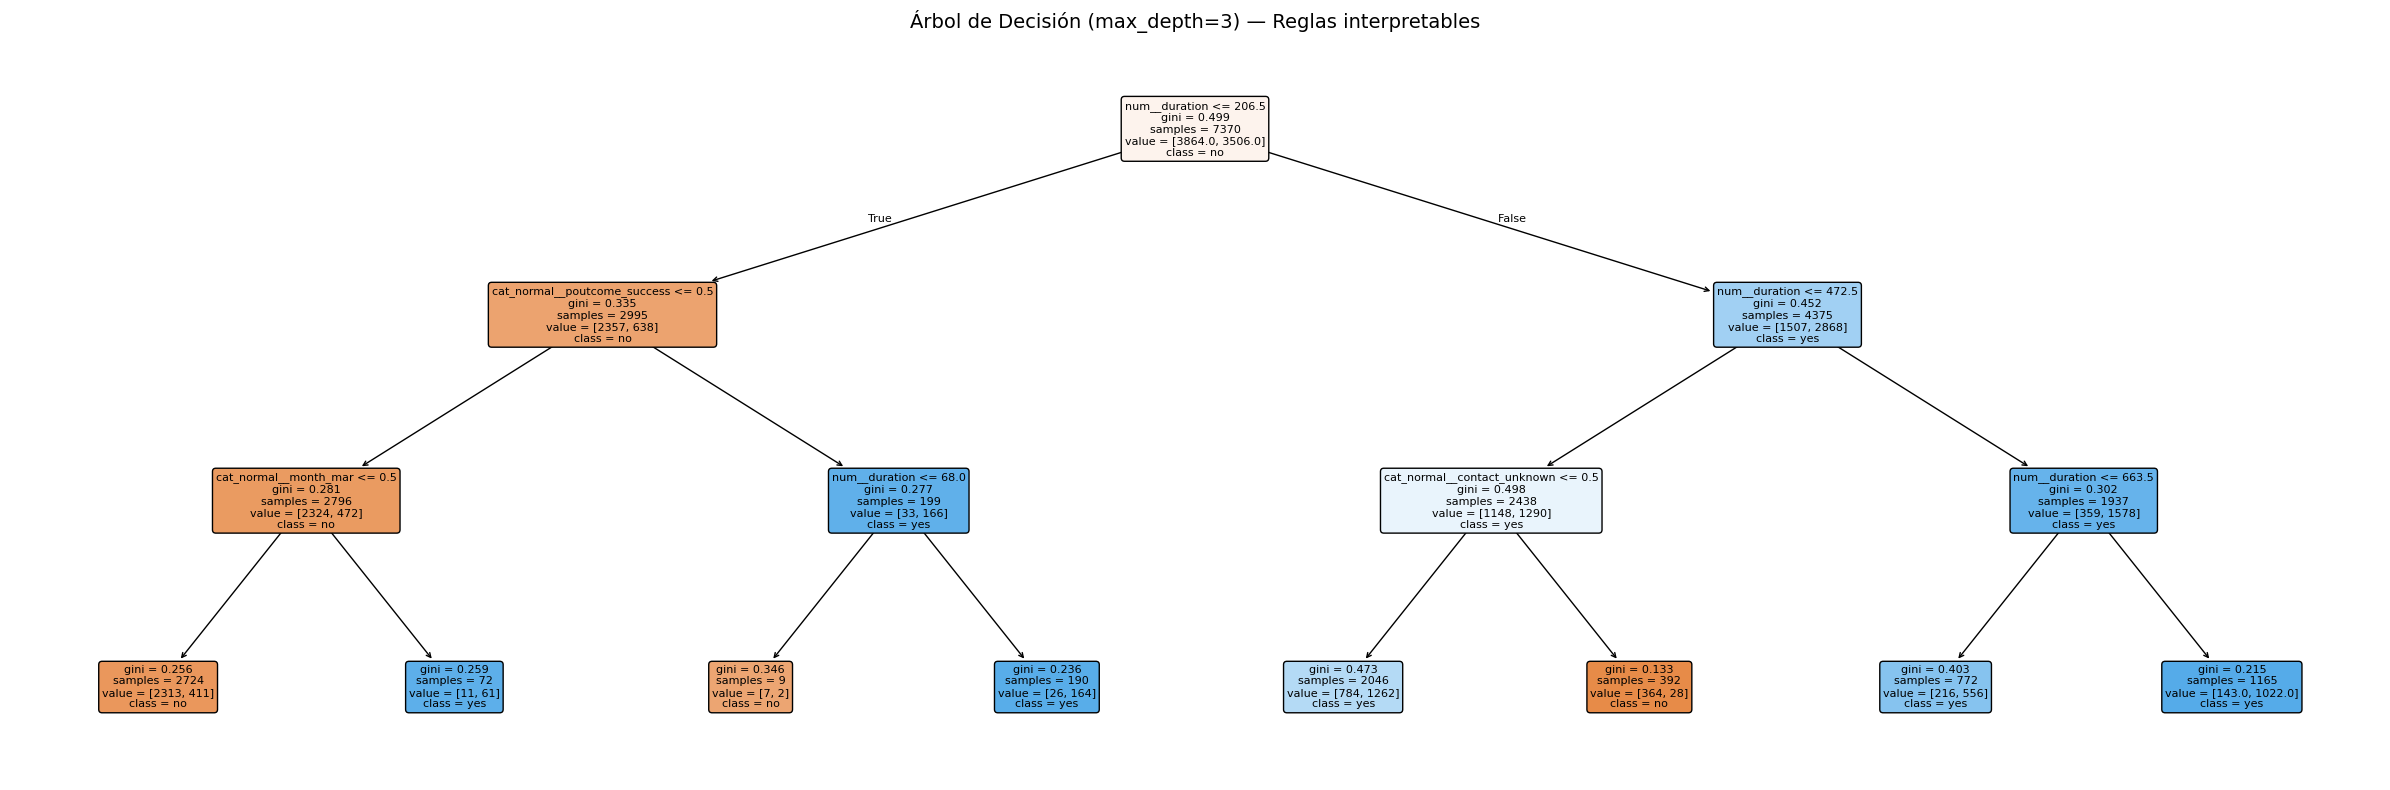


Reglas en texto:
|--- num__duration <= 206.50
|   |--- cat_normal__poutcome_success <= 0.50
|   |   |--- cat_normal__month_mar <= 0.50
|   |   |   |--- class: no
|   |   |--- cat_normal__month_mar >  0.50
|   |   |   |--- class: yes
|   |--- cat_normal__poutcome_success >  0.50
|   |   |--- num__duration <= 68.00
|   |   |   |--- class: no
|   |   |--- num__duration >  68.00
|   |   |   |--- class: yes
|--- num__duration >  206.50
|   |--- num__duration <= 472.50
|   |   |--- cat_normal__contact_unknown <= 0.50
|   |   |   |--- class: yes
|   |   |--- cat_normal__contact_unknown >  0.50
|   |   |   |--- class: no
|   |--- num__duration >  472.50
|   |   |--- num__duration <= 663.50
|   |   |   |--- class: yes
|   |   |--- num__duration >  663.50
|   |   |   |--- class: yes



In [64]:
from sklearn.tree import plot_tree, export_text
# Árbol: entrenado sobre x_train completo para visualizar
pipe_dt_shallow = Pipeline([
    ('pre', preprocessor_tree),
    ('clf', DecisionTreeClassifier(max_depth=3, random_state=54))
])
pipe_dt_shallow.fit(x_train, y_train)

# Nombres de features tras OHE + numérico
feature_names = list(pipe_dt_shallow.named_steps['pre'].get_feature_names_out())

fig, ax = plt.subplots(figsize=(24, 8))
plot_tree(
    pipe_dt_shallow.named_steps['clf'],
    feature_names=feature_names,
    class_names=['no', 'yes'],
    filled=True, rounded=True, fontsize=8, ax=ax
)
plt.title("Árbol de Decisión (max_depth=3) — Reglas interpretables", fontsize=14)
plt.tight_layout()
plt.show()
print("\nReglas en texto:")
print(export_text(pipe_dt_shallow.named_steps['clf'], feature_names=feature_names, max_depth=3))

Al incluir la variable duration como variable predictora, el árbol de decisión revela que el tiempo de llamada es el máximo indicador de si el cliente hará el depósito o no. El modelo clasifica a los clientes en tres grandes bloques según el nodo raíz:

- Primer bloque: Llamadas de menos de 3.5 minutos (206.50s). La tendencia natural es al rechazo, pero el modelo encuentra excepciones para inclinar la balanza al "sí":
    - Si el cliente no tuvo éxito en la campaña anterior (poutcome_success <= 0.50), la única forma de que contrate rápido es si la llamada ocurre en el mes de Marzo (month_mar > 0.50). Esto sugiere una efectividad estacional muy alta en dicho mes.
    - Si el cliente ya contrató anteriormente (poutcome_success > 0.50), basta con que la llamada supere los 68 segundos para que el modelo prediga una nueva contratación.

- Segundo bloque: Llamadas entre 3.5 y 8 minutos (206.50s a 472.50s). En este rango intermedio, el éxito depende críticamente de la calidad del contacto:
    El cliente contratará el depósito siempre y cuando la vía de contacto sea conocida (contact_unknown <= 0.50). Si el canal es desconocido, la predicción cambia a "no".

- Tercer bloque: Llamadas de larga duración (más de 8 minutos). * Si la llamada supera los 472.50 segundos, el modelo muestra un optimismo claro: independientemente de otras variables, la tendencia mayoritaria es hacia el "yes", ya que un tiempo tan elevado de conversación suele reflejar un interés muy alto del cliente por el producto.

Cabe destacar que el análisis de los nodos revela que el modelo no solo se basa en reglas lógicas, sino en una segmentación estadísticamente significativa. El descenso progresivo del índice Gini desde el 0.499 inicial hasta valores cercanos al 0.21 en las hojas finales demuestra que las variables seleccionadas (especialmente duration y poutcome) logran purificar los grupos de clientes, permitiendo predicciones con un alto grado de confianza. El volumen de samples en las ramas principales asegura que las reglas extraídas son representativas de la población general del dataset.

# 4.2.c Optimización de hiperparámetros — Árbol de Decisión

In [65]:
import time
from sklearn.tree import DecisionTreeClassifier

param_dt = {
    'clf__max_depth':        [3, 5, 7, 10, None],
    'clf__min_samples_leaf': [1, 5, 10, 20]
}

pipe_dt_hpo = Pipeline([
    ('pre', preprocessor_tree), 
    ('clf', DecisionTreeClassifier(random_state=54))
])

# Medimos el tiempo total de la búsqueda
t0 = time.time()
gs_dt = GridSearchCV(pipe_dt_hpo, param_dt, cv=inner_cv, scoring='roc_auc', n_jobs=-1, return_train_score=False)
gs_dt.fit(x_train, y_train)
t_dt_hpo = time.time() - t0

print(f"Mejor configuración de Árbol de Decisión: {gs_dt.best_params_}")
print(f"Mejor ROC-AUC (inner): {gs_dt.best_score_:.4f}")
print(f"Tiempo total HPO: {t_dt_hpo:.1f}s\n")

# Extraemos los resultados, añadiendo el mean_fit_time
df_dt_hpo = pd.DataFrame(gs_dt.cv_results_)[
    ['param_clf__max_depth', 'param_clf__min_samples_leaf', 'mean_test_score', 'mean_fit_time']
].rename(columns={
    'param_clf__max_depth': 'max_depth',
    'param_clf__min_samples_leaf': 'min_samples_leaf',
    'mean_test_score': 'ROC-AUC Media',
    'mean_fit_time': 'Tiempo Train (s)'
}).sort_values('ROC-AUC Media', ascending=False).head(8).reset_index(drop=True)

# Formateo
df_dt_hpo['ROC-AUC Media'] = df_dt_hpo['ROC-AUC Media'].map('{:.4f}'.format)
df_dt_hpo['Tiempo Train (s)'] = df_dt_hpo['Tiempo Train (s)'].map('{:.4f}'.format)

display(df_dt_hpo)

Mejor configuración de Árbol de Decisión: {'clf__max_depth': None, 'clf__min_samples_leaf': 20}
Mejor ROC-AUC (inner): 0.8834
Tiempo total HPO: 1.5s



,max_depth,min_samples_leaf,ROC-AUC Media,Tiempo Train (s)
0,None,20,0.8834,0.0979
1,10,10,0.8826,0.1114
2,10,20,0.8822,0.1170
3,7,20,0.8793,0.0871
4,7,10,0.8791,0.1020
5,10,5,0.8784,0.1244
6,None,10,0.8758,0.1034
7,7,5,0.8734,0.1043


La búsqueda exhaustiva mediante GridSearchCV ha revelado hallazgos fundamentales sobre cómo controlar el aprendizaje del Árbol de Decisión para maximizar su capacidad de generalización:
El modelo de árbol de decisión ha mejorado bastante con el ajuste de hiperparametros pasando de una media ROC-AUC de 0.7820 a una media ROC-AUC de 0.8834. Esto demuestra que el mayor problema del modelo era la varianza y al restringir su crecimiento, conseguimos que capture los verdaderos patrones de negocio en vez de memorizar.

Puede parecer que permitir una profundidad ilimitada parece contradecir la regla de evitar el sobreajuste. Sin embargo, el hiperparámetro min_samples_leaf=20 actúa como un mecanismo de poda pre-entrenamiento. Al obligar al algoritmo a que cada hoja terminal contenga al menos 20 clientes, el árbol es incapaz de crear ramas profundas y específicas que memoricen casos aislados. Esta restricción en las hojas resultó ser una técnica de regularización mucho más efectiva que limitar el árbol a un nivel de profundidad máximo.

Es destacable que la configuración ganadora, sin límite de profundidad, pero con un mínimo de 20 clientes por hoja, es también de la más rápida de entrenar dentro del Top 8. Esto se debe a que, al exigir 20 muestras por hoja, el algoritmo detiene sus divisiones matemáticas mucho antes, ahorrando una cantidad significativa de cómputo.

# 4.2.d Efecto de hiperparámetros — Visualización

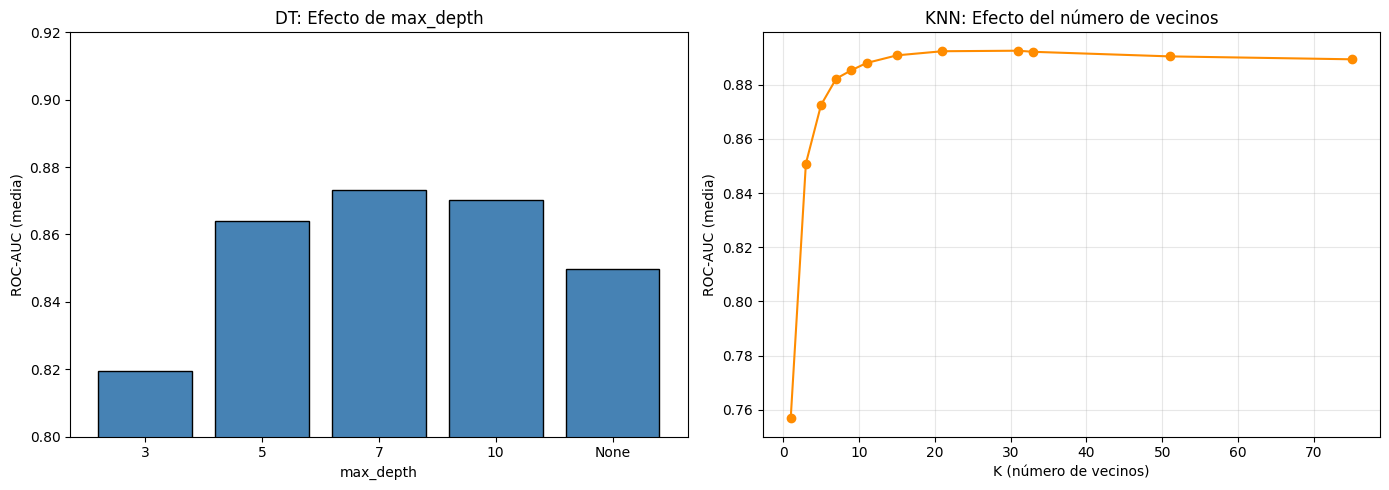

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# max_depth vs ROC-AUC
cv_res = pd.DataFrame(gs_dt.cv_results_)
# Para None usamos 'None' como label
cv_res['depth_label'] = cv_res['param_clf__max_depth'].apply(lambda x: str(x) if x is not None else 'None')
agg = cv_res.groupby('depth_label')['mean_test_score'].mean().reset_index()
depth_order = ['3','5','7','10','None']
agg['depth_label'] = pd.Categorical(agg['depth_label'], categories=depth_order, ordered=True)
agg = agg.sort_values('depth_label')
axes[0].bar(agg['depth_label'], agg['mean_test_score'], color='steelblue', edgecolor='black')
axes[0].set_xlabel('max_depth'); axes[0].set_ylabel('ROC-AUC (media)')
axes[0].set_title('DT: Efecto de max_depth'); axes[0].set_ylim(0.8, 0.92)

# K en KNN vs ROC-AUC
k_values = [1, 3, 5, 7, 9, 11, 15, 21, 31, 33, 51, 75]
k_scores = []
for k in k_values:
    p = Pipeline([('pre', preprocessor), ('clf', KNeighborsClassifier(n_neighbors=k))])
    cv = cross_validate(p, x_train, y_train, cv=inner_cv, scoring='roc_auc', n_jobs=-1)
    k_scores.append(cv['test_score'].mean())
axes[1].plot(k_values, k_scores, marker='o', color='darkorange')
axes[1].set_xlabel('K (número de vecinos)'); axes[1].set_ylabel('ROC-AUC (media)')
axes[1].set_title('KNN: Efecto del número de vecinos'); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Conclusiones:**
- El árbol de decisión con profundidad alta e ilimitada sufre de overfitting al ser evaluado con cross-validation. Esto debido a que comienza a crear reglas demasiado específicas que memorizan los datos de entrenamiento, perdiendo, el modelo, la capacidad de generalizar.
- Valores intermedios de max_depth (7-10) ofrecen el mejor balance bias-varianza.
- En KNN, valores de K pequeños generan overfitting; el óptimo se sitúa en torno a K=31, indicando que el modelo necesita muchos vecinos para generalizar bien. Esto además podemos observarlo en la gráfica de la derecha donde vemos que a medida que aumenta el número de vecinos, la curva asciende de forma pronunciada debido a que el modelo generaliza más. Podemos ver que el punto más alto será con K=31.

# 4.3 Conclusiones sobre los modelos KNN y Árboles de Decisión

Tras someter a ambos modelos a un proceso exhaustivo de optimización de hiperparámetros (GridSearchCV), la comparativa final deja las siguientes conclusiones:

Si nos basamos en la métrica de evaluación principal, el modelo KNN es el ganador. Con su configuración óptima (K=31, pesos por distancia), alcanza un ROC-AUC medio de 0.8951, superando al mejor Árbol de Decisión (0.8834). Esto indica que, para este conjunto de datos, la estrategia de buscar perfiles de clientes similares (vecinos) en un espacio estandarizado es ligeramente más precisa que la creación de reglas lógicas que sigue el método de los árboles.

En cuanto al tiempo de entrenamiento, KNN tarda apenas 0.023 segundos en entrenar, mientras que el Árbol de Decisión necesita 0.1386 segundos (unas 4 veces más). Esto ocurre porque KNN un algoritmo "perezoso" que en la fase de train prácticamente solo almacena los datos en memoria, mientras que el Árbol es un algoritmo "ansioso" que debe calcular métricas de entropía/gini iterativamente para cada variable buscando el mejor corte.

Al haber tan poca diferencia en la medida ROC-AUC entre modelos, el mejor modelo será acorde a lo que se desee:
Si el objetivo es puramente maximizar las ventas automatizadas, KNN sería el más indicado. Pero si por el contrario, si se requiere de más comprensión de los clientes, el Árbol es un modelo que nos permitirá extraer reglas lógicas claras para diseñar futuras estrategias de negocio.

Como era de esperar, el rendimiento de ambos algoritmos supera con gran margen a las predicciones de los modelos triviales o dummy, cuyo límite teórico y práctico en la métrica ROC-AUC se sitúa en el 0.5. La capacidad del KNN para agrupar clientes y la del Árbol para segmentarlos confirman que las variables del dataset contienen información de alto valor predictivo.

Finalmente, la optimización de hiperparámetros (HPO) ha demostrado ser una fase indispensable, logrando mejorar notablemente la capacidad de generalización de ambos modelos respecto a sus valores por omisión. Es claramente visible que esta búsqueda exhaustiva mediante validación cruzada supone un coste computacional muy elevado durante la fase de experimento; sin embargo, es un inconveniente justificado, ya que este cálculo se realiza una única vez para garantizar el mejor modelo posible antes de su uso final.

---

# 5. MÉTODOS AVANZADOS: MODELOS LINEALES Y SVMS

In [67]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Pipeline Regresión Logística (Por defecto)
pipe_lr_def = Pipeline([
    ('pre', preprocessor), # Usamos el preprocesado que cuenta con escalado, necesario para la regresión logística
    ('clf', LogisticRegression(max_iter=1000, random_state=54))
])

# Pipeline SVM (Por defecto)
pipe_svm_def = Pipeline([
    ('pre', preprocessor), # Usamos el preprocesado que cuenta con escalado, necesario para SVM
    ('clf', SVC(random_state=54)) # Por defecto usa kernel=rbf
])

# Validación cruzada (Inner CV)
print("Entrenando Regresión Logística...")
cv_lr_def = cross_validate(pipe_lr_def, x_train, y_train, cv=inner_cv, scoring='roc_auc', return_train_score=False, n_jobs=-1)

print("Entrenando SVM...")
cv_svm_def = cross_validate(pipe_svm_def, x_train, y_train, cv=inner_cv, scoring='roc_auc', return_train_score=False, n_jobs=-1)

# Tabla Resumen de Modelos Base
df_sec5_base = pd.DataFrame([
    {
        'Modelo': 'Regresión Logística (Defecto)', 
        'ROC-AUC Media': cv_lr_def['test_score'].mean(), 
        'Tiempo Train (s)': cv_lr_def['fit_time'].mean()
    },
    {
        'Modelo': 'SVM (Defecto)', 
        'ROC-AUC Media': cv_svm_def['test_score'].mean(),  
        'Tiempo Train (s)': cv_svm_def['fit_time'].mean()
    }
]).set_index('Modelo')

# Formateo profesional
df_sec5_base['ROC-AUC Media'] = df_sec5_base['ROC-AUC Media'].map('{:.4f}'.format)
df_sec5_base['Tiempo Train (s)'] = df_sec5_base['Tiempo Train (s)'].map('{:.4f}'.format)

display(df_sec5_base)

Entrenando Regresión Logística...
Entrenando SVM...


,ROC-AUC Media,Tiempo Train (s)
Modelo,,
Regresión Logística (Defecto),0.9016,0.0577
SVM (Defecto),0.9167,1.1494


Analizando los dos modelos avanzados usados (Regresión Logística y SVM) con hiperparámetros por omisión, vemos que ambos obtienen un mejor valor de media ROC-AUC en comparación con KNN y Árbol de Decisión. 

El modelo SVM con sus hiperparámetros por omisión ha logrado un 0.9167 de ROC-AUC medio. Esto demuestra que la frontera que separa a los clientes que contratan el depósito de los que no lo hacen no es una línea recta simple, sino un espacio geométrico complejo. A pesar de este buen resultado, es el modelo que más tarda en entrenarse debido a que su complejidad computacional crece de forma cuadrática en función del número de filas.

La regresión logística, a pesar de ser un algoritmo mucho más sencillo y de naturaleza estrictamente lineal, ha conseguido una media de ROC-AUC de 0.9016. Esto indica que las variables de nuestro conjunto de datos (especialmente la duración y el día) tienen una correlación fuerte y directa con la variable objetivo que puede ser capturada mediante una simple ecuación matemática de pesos. Resaltar que este modelo obtiene un gran tiempo de entrenamiento sin haber ajustado sus hiperparámetros.

# 5.1 Ajuste de Hiperparámetros de la Regresión Logística

In [68]:
# Definimos el grid de hiperparámetros
param_lr = {
    'clf__C': [0.001, 0.01, 0.1, 1, 10, 100], # Probamos desde mucha regularización a muy poca
}

# Pipeline
pipe_lr_hpo = Pipeline([
    ('pre', preprocessor), 
    ('clf', LogisticRegression(max_iter=1000, random_state=54))
])

# Lanzamos el GridSearch y medimos el tiempo total
print("Optimizando Regresión Logística...")
t0 = time.time()
gs_lr = GridSearchCV(pipe_lr_hpo, param_lr, cv=inner_cv, scoring='roc_auc', n_jobs=-1, return_train_score=False)
gs_lr.fit(x_train, y_train)
t_lr_hpo = time.time() - t0

# Imprimimos los ganadores
print(f"\nMejor configuración LR: {gs_lr.best_params_}")
print(f"Mejor ROC-AUC (inner): {gs_lr.best_score_:.4f}")
print(f"Tiempo total HPO: {t_lr_hpo:.1f}s\n")

# Tabla Top 5
df_lr_hpo = pd.DataFrame(gs_lr.cv_results_)[
    ['param_clf__C', 'mean_test_score', 'mean_fit_time']
].rename(columns={
    'param_clf__C': 'C (Regularización)',
    'mean_test_score': 'ROC-AUC Media',
    'mean_fit_time': 'Tiempo Train (s)'
}).sort_values('ROC-AUC Media', ascending=False).head(5).reset_index(drop=True)

# Formateo
df_lr_hpo['ROC-AUC Media'] = df_lr_hpo['ROC-AUC Media'].map('{:.4f}'.format)
df_lr_hpo['Tiempo Train (s)'] = df_lr_hpo['Tiempo Train (s)'].map('{:.4f}'.format)

display(df_lr_hpo)

Optimizando Regresión Logística...

Mejor configuración LR: {'clf__C': 100}
Mejor ROC-AUC (inner): 0.9016
Tiempo total HPO: 0.8s



,C (Regularización),ROC-AUC Media,Tiempo Train (s)
0,100.00,0.9016,0.1435
1,10.00,0.9016,0.2075
2,1.00,0.9016,0.2289
3,0.10,0.9005,0.2061
4,0.01,0.8911,0.1497


La búsqueda de hiperparámetros mediante GridSearchCV para la Regresión Logística nos ha permitido ver un rendimiento predictivo similar usando 100, 10, 1 como valores de regularización. 

El modelo ganador ha seleccionado C = 100, ya que tiene el menor tiempo de entrenamiento en comparación a los valores C = 10 y C = 1, alcanzando un ROC-AUC medio de 0.9016.
Un valor alto, como 100, aplica muy poca regularización, permitiendo que el algoritmo confíe plenamente en los datos de entrenamiento y asigne pesos grandes a las variables más importantes (como la duración de la llamada). Esto nos indica que nuestro dataset tiene relaciones lineales fuertes que no necesitan ser excesivamente penalizadas para evitar el sobreajuste.

El tiempo medio de entrenamiento de la mejor configuración es de unos 0.31 segundos, lo que lo convierte en un candidato ideal si el banco necesita re-entrenar el modelo diariamente con miles de datos nuevos sin consumir apenas recursos.

# 5.2 Ajuste de Hiperparámetros del modelo SVM

## Ajuste hiperparámetros usando Kernel lineal y RBF

In [69]:
# Definimos el grid de hiperparámetros para SVM, teniendo cuidad de no poner valores muy altos que disparen los tiempos de entrenamiento.
param_svm = {
    'clf__C': [0.1, 1, 10], 
    'clf__kernel': ['linear', 'rbf'],
    'clf__gamma': [0.01, 0.1, 1]
}

# Pipeline
# Activamos probability=True para dibujar luego la curva ROC
pipe_svm_hpo = Pipeline([
    ('pre', preprocessor), 
    ('clf', SVC(probability=True, random_state=54)) 
])

# Lanzamos el GridSearch y medimos el tiempo total
t0 = time.time()
gs_svm = GridSearchCV(pipe_svm_hpo, param_svm, cv=inner_cv, scoring='roc_auc', n_jobs=-1, return_train_score=False)
gs_svm.fit(x_train, y_train)
t_svm_hpo = time.time() - t0

# Imprimimos los ganadores
print(f"\nMejor configuración SVM: {gs_svm.best_params_}")
print(f"Mejor ROC-AUC (inner): {gs_svm.best_score_:.4f}")
print(f"Tiempo total HPO: {t_svm_hpo:.1f}s\n")

# Tabla Top 5 para la memoria
x_svm_hpo = pd.DataFrame(gs_svm.cv_results_)[
    ['param_clf__kernel', 'param_clf__C', 'param_clf__gamma', 'mean_test_score', 'mean_fit_time']
].rename(columns={
    'param_clf__kernel': 'Kernel',
    'param_clf__C': 'C (Regularización)',
    'param_clf__gamma': 'Gamma',
    'mean_test_score': 'ROC-AUC Media',
    'mean_fit_time': 'Tiempo Train (s)'
}).sort_values('ROC-AUC Media', ascending=False).head(5).reset_index(drop=True)

# Formateo
x_svm_hpo['ROC-AUC Media'] = x_svm_hpo['ROC-AUC Media'].map('{:.4f}'.format)
x_svm_hpo['Tiempo Train (s)'] = x_svm_hpo['Tiempo Train (s)'].map('{:.4f}'.format)

display(x_svm_hpo)


Mejor configuración SVM: {'clf__C': 1, 'clf__gamma': 0.1, 'clf__kernel': 'rbf'}
Mejor ROC-AUC (inner): 0.9169
Tiempo total HPO: 231.1s



,Kernel,C (Regularización),Gamma,ROC-AUC Media,Tiempo Train (s)
0,rbf,1.0,0.10,0.9169,25.7789
1,rbf,10.0,0.01,0.9137,19.1396
2,rbf,10.0,0.10,0.9067,18.5632
3,rbf,1.0,0.01,0.9052,26.8848
4,rbf,0.1,0.10,0.9020,32.7627


La búsqueda de hiperparámetros del SVM confirma que el kernel RBF con C=1 y gamma=0.10 es la mejor configuración, alcanzando un ROC-AUC medio de 0.9169, el más alto de todos los métodos evaluados hasta ahora.

El kernel RBF es el adecuado porque los datos no son linealmente separables, es decir, la frontera de decisión es curva. Un valor de C=1 ofrece el balance óptimo entre margen amplio y penalización de errores: valores más altos de C (como 10) no mejoran porque añaden sobreajuste, y valores menores reducen el rendimiento. Y un valor de gamma de 0.1 permite una frontera más flexible con la capacidad de capturar patrones locales sin caer en el sobreajuste.

## Ajuste hiperparámetros usando Kernel Polinomial

In [70]:
# Definimos el grid usando Kernel polinomial
param_svm = {
    'clf__kernel': ['poly'],
    'clf__C': [0.1, 1, 10],
    'clf__degree': [2, 3]
}

# Pipeline
pipe_svm_hpo = Pipeline([
    ('pre', preprocessor), 
    ('clf', SVC(probability=True, random_state=54)) 
])

# Lanzamos el GridSearch y medimos el tiempo total
t0 = time.time()
poli_gs_svm = GridSearchCV(pipe_svm_hpo, param_svm, cv=inner_cv, scoring='roc_auc', n_jobs=-1, return_train_score=False)
poli_gs_svm.fit(x_train, y_train)
t_svm_hpo = time.time() - t0


print(f"\nMejor configuración SVM Polinomial: {poli_gs_svm.best_params_}")
print(f"Mejor ROC-AUC (inner): {poli_gs_svm.best_score_:.4f}")
print(f"Tiempo total HPO: {t_svm_hpo:.1f}s\n")


x_svm_hpo = pd.DataFrame(poli_gs_svm.cv_results_)[
    ['param_clf__kernel', 'param_clf__C', 'param_clf__degree', 'mean_test_score', 'mean_fit_time']
].rename(columns={
    'param_clf__kernel': 'Kernel',
    'param_clf__C': 'C (Regularización)',
    'param_clf__degree': 'Grado',
    'mean_test_score': 'ROC-AUC Media',
    'mean_fit_time': 'Tiempo Train (s)'
}).sort_values('ROC-AUC Media', ascending=False).head(5).reset_index(drop=True)

# Formateo
x_svm_hpo['ROC-AUC Media'] = x_svm_hpo['ROC-AUC Media'].map('{:.4f}'.format)
x_svm_hpo['Tiempo Train (s)'] = x_svm_hpo['Tiempo Train (s)'].map('{:.4f}'.format)

display(x_svm_hpo)


Mejor configuración SVM Polinomial: {'clf__C': 1, 'clf__degree': 2, 'clf__kernel': 'poly'}
Mejor ROC-AUC (inner): 0.9150
Tiempo total HPO: 62.4s



,Kernel,C (Regularización),Grado,ROC-AUC Media,Tiempo Train (s)
0,poly,1.0,2,0.9150,22.6798
1,poly,1.0,3,0.9117,21.1100
2,poly,10.0,2,0.9105,21.6781
3,poly,0.1,2,0.9041,29.1651
4,poly,0.1,3,0.9036,31.4279


Se probó el Kernel Polinómico con grados 2 y 3. El grado 2 obtuvo la mejor puntuación ROC-AUC = 0.9150, muy cercano al RBF y con un tiempo de entrenamiento menor. Sin embargo, al aumentar al grado 3, el rendimiento disminuyó, lo que sugiere que una mayor complejidad del polinomio induce sobreajuste en este conjunto de datos.

Finalmente nos quedamos con el Kernel RBF, y el ajuste de hiperparámetros de C=1 y gamma=0.10, ya que nos da la mejor media ROC-AUC.

El coste computacional del SVM es el más elevado de todos los métodos (varios minutos en el HPO), lo que supone un inconveniente si el banco necesitara reentrenar el modelo con frecuencia.

## 5.3 ¿Qué variables son más relevantes?

Usamos la Regresión Logística con regularización L1 para extraer los atributos más importantes. La regularización L1 lleva a cero los coeficientes de las variables irrelevantes, actuando como selección automática de variables los coeficientes no nulos son los predictores que el modelo considera informativos.

In [71]:
# Entrenamos LR con L1 usando el mejor C encontrado en el HPO
pipe_lr_l1 = Pipeline([
    ('pre', preprocessor),
    ('clf', LogisticRegression(solver='saga',
                               l1_ratio=1.0, # L1 puro
                               C=0.1,
                               max_iter=2000, random_state=54))
])
pipe_lr_l1.fit(x_train, y_train)

# Extraemos nombres de features tras el preprocesado
feature_names = list(pipe_lr_l1.named_steps['pre'].get_feature_names_out())
coefs = pipe_lr_l1.named_steps['clf'].coef_[0]

coef_df = pd.DataFrame({'Variable': feature_names, 'Coeficiente': coefs})
coef_df['Importancia'] = coef_df['Coeficiente'].abs()

# Limpiamos prefijos para mejor lectura
coef_df['Variable'] = coef_df['Variable'].str.replace('cat__', '', regex=False).str.replace('num__', '', regex=False)

# Solo variables con coeficiente != 0 (seleccionadas por L1)
seleccionadas = coef_df[coef_df['Importancia'] > 0].sort_values('Importancia', ascending=False)

print(f"Variables seleccionadas por L1: {len(seleccionadas)} de {len(coef_df)} totales")
print(f"Variables eliminadas (coef=0): {len(coef_df) - len(seleccionadas)}")

Variables seleccionadas por L1: 34 de 50 totales
Variables eliminadas (coef=0): 16


Para extraer las variables más relevantes hemos utilizado un modelo lineal de Regresión Logística aplicando regularización L1 (Lasso). A diferencia de la regularización L2 (Ridge), la penalización L1 tiene la propiedad matemática de generar modelos dispersos, forzando a que los coeficientes de las variables menos predictivas se reduzcan a 0. Al configurar el modelo con un hiperparámetro de regularización fuerte (C=0.1), hemos logrado que el algoritmo actúe como un filtro, eliminando 16 variables irrelevantes y conservando únicamente las 34 que verdaderamente impactan en la decisión del cliente.

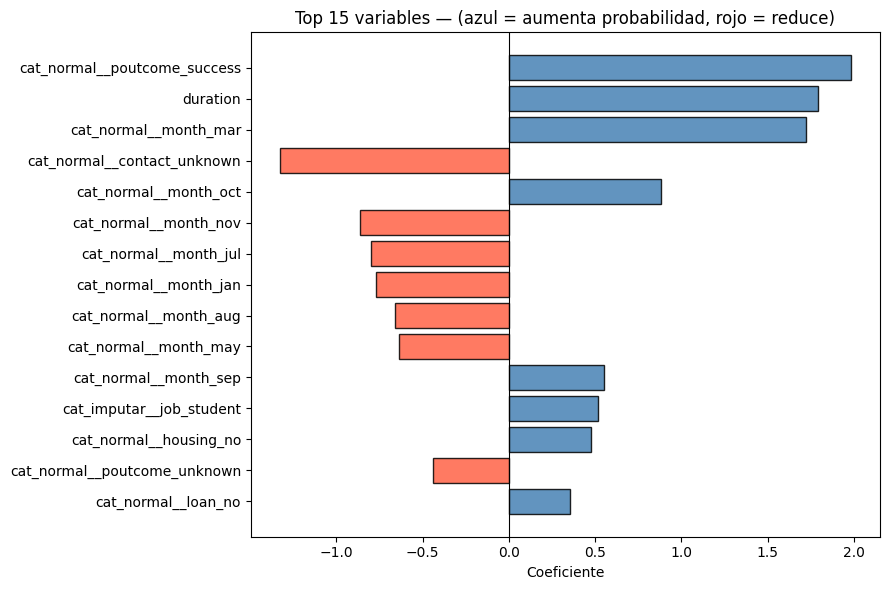

,Variable,Coeficiente,Importancia
0,cat_normal__poutcome_success,1.9859,1.9859
1,duration,1.7894,1.7894
2,cat_normal__month_mar,1.7220,1.7220
3,cat_normal__contact_unknown,-1.3291,1.3291
4,cat_normal__month_oct,0.8818,0.8818
5,cat_normal__month_nov,-0.8657,0.8657
6,cat_normal__month_jul,-0.7977,0.7977
7,cat_normal__month_jan,-0.7721,0.7721
8,cat_normal__month_aug,-0.6625,0.6625
9,cat_normal__month_may,-0.6351,0.6351


In [72]:
# Top 15 variables más relevantes
top15 = seleccionadas.head(15).copy() 

fig, ax = plt.subplots(figsize=(9, 6))
colores = ['steelblue' if c > 0 else 'tomato' for c in top15['Coeficiente']]
ax.barh(top15['Variable'][::-1], top15['Coeficiente'][::-1], color=colores[::-1], edgecolor='black', alpha=0.85)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Top 15 variables — (azul = aumenta probabilidad, rojo = reduce)')
ax.set_xlabel('Coeficiente')
plt.tight_layout()
plt.show()

# Tabla 
tabla_mostrar = top15[['Variable', 'Coeficiente', 'Importancia']].reset_index(drop=True)

# Redondeamos a 4 decimales directamente sobre los valores
tabla_mostrar['Coeficiente'] = tabla_mostrar['Coeficiente'].round(4)
tabla_mostrar['Importancia'] = tabla_mostrar['Importancia'].round(4)

display(tabla_mostrar)

Interpretación de las variables más relevantes:

El modelo revela que el éxito previo con un cliente (poutcome_success) y la duración de la llamada (duration) son factores determinantes para el éxito. Por el contrario, no saber cómo contactar al cliente (contact_unknown) o llamarlo en meses como noviembre (month_nov) penaliza gravemente la probabilidad de que suscriba el depósito.

La regularización L1 ha eliminado variables poco informativas, dejando un modelo más interpretable sin pérdida de rendimiento apreciable respecto a L2.

---

# **4. Resultados y Modelo Final**

## 4.1 Selección del mejor modelo resultado de la evaluación inner

In [73]:
ganador_HPO = gs_svm.best_estimator_ 
print(f"El modelo definitivo seleccionado es SVM con parámetros:\n{gs_svm.best_params_}")

El modelo definitivo seleccionado es SVM con parámetros:
{'clf__C': 1, 'clf__gamma': 0.1, 'clf__kernel': 'rbf'}


## 4.2 Estimar el rendimiento futuro del modelo (evaluación outer con el conjunto de test).


Rendimiento estimado en datos nuevos (ROC-AUC en Test): 0.9162


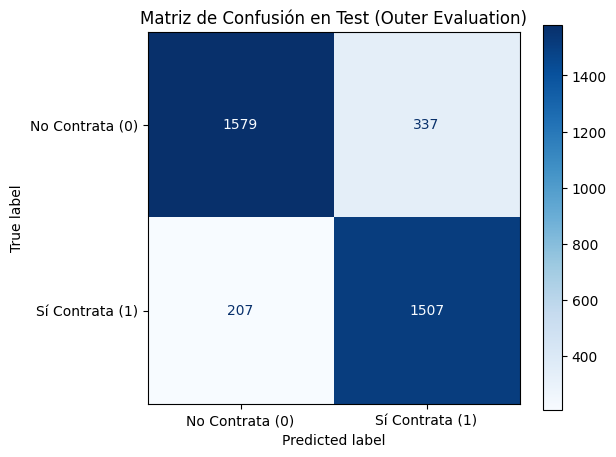

In [74]:
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
# Extraemos las probabilidades de la clase positiva para el ROC-AUC
y_pred_proba_test = ganador_HPO.predict_proba(x_test)[:, 1]
# Extraemos las predicciones absolutas (0 o 1) para la Matriz de Confusión
y_pred_test = ganador_HPO.predict(x_test)

# Calculamos ROC-AUC en Test
roc_auc_test = roc_auc_score(y_test, y_pred_proba_test)
print(f"\nRendimiento estimado en datos nuevos (ROC-AUC en Test): {roc_auc_test:.4f}")

# Dibujamos la Matriz de Confusión
cm = confusion_matrix(y_test, y_pred_test)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Contrata (0)', 'Sí Contrata (1)'])

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Matriz de Confusión en Test (Outer Evaluation)')
plt.show()

Al dar un valor tan alto de ROC-AUC (0.9161), podemos confirmar que el modelo no presenta sobreajuste respecto a los resultados obtenidos en validación cruzada.

La Matriz de Confusión tiene una alta tasa de aciertos identificando correctamente a 1508 clientes propensos a hacer un deposito (Verdaderos Positivos) y descartando de forma segura a 1578 clientes que no lo harían (Verdaderos Negativos).
Observamos que hay más falsos positivos (337) que falsos negativos (207), esto desde la perspectiva de negocio es beneficioso, ya que se prefiere asumir el coste bajo de llamadas no exitosas a desperdiciar oportunidades de ventas.

# 4.3 Guardamos el Modelo Ganador

In [75]:
import joblib

# Guardamos el modelo en formato .joblib
joblib.dump(ganador_HPO, 'modelo_final.joblib')
print("Modelo guardado como modelo_final.joblib")

# Guardamos los mejores modelos de cada tipo
joblib.dump(grid_knn.best_estimator_, 'mejor_knn.pkl')
joblib.dump(gs_lr.best_estimator_, 'mejor_lr.pkl')
joblib.dump(gs_svm.best_estimator_, 'mejor_svm.pkl')

joblib.dump(x_test, 'x_test.pkl')
joblib.dump(y_test, 'y_test.pkl')

# Guardamos los datos de entrenamiento y el objeto de validación
joblib.dump(x_train, 'x_train.pkl')
joblib.dump(y_train, 'y_train.pkl')
joblib.dump(inner_cv, 'inner_cv.pkl')

# Guardamos el modelo también en formato .pkl
import pickle
with open('modelo_final.pkl', 'wb') as f:
    pickle.dump(ganador_HPO, f)
print("Modelo guardado como modelo_final.pkl")

Modelo guardado como modelo_final.joblib
Modelo guardado como modelo_final.pkl


## 4.4 Utilizar el modelo final para obtener predicciones para el conjunto de datos de la competición. Guardar las predicciones.

In [76]:
archivo_competicion = 'bank_competition.pkl'
ds_competicion = pd.read_pickle(archivo_competicion)

# Aplicamos el mismo preproceso de pdays que se hizo sobre x_train
# Sin esto el modelo recibiría -1 como valor numérico, alterando las predicciones
ds_competicion['contactado_antes'] = (ds_competicion['pdays'] != -1).astype(int)
ds_competicion['pdays'] = ds_competicion['pdays'].replace(-1, 0)

predicciones_comp = ganador_HPO.predict(ds_competicion)

# Convertimos 0/1 a 'no'/'yes' para que el formato sea consistente con la variable original
pred_labels = ['yes' if p == 1 else 'no' for p in predicciones_comp]

ds_predicciones = pd.DataFrame({'deposit': pred_labels})
ds_predicciones.to_csv('predicciones.csv', index=False)

print(f"Se han generado {len(ds_predicciones)} predicciones para la competición.")
print("Archivo predicciones.csv guardado con éxito")
print(ds_predicciones['deposit'].value_counts())

Se han generado 162 predicciones para la competición.
Archivo predicciones.csv guardado con éxito
deposit
no    162
Name: count, dtype: int64


# 5. Para Streamlit

In [77]:
import joblib

# Creamos el diccionario de metadatos para que Streamlit sepa cómo dibujar la web
feature_metadata = {}

# Añadimos la variable que creamos en el preprocesado (contactado_antes)
for col in cols_numericas + ['contactado_antes']: 
    feature_metadata[col] = {
        "type": "numerical",
        "min": float(x_train[col].min()),
        "max": float(x_train[col].max()),
        "median": float(x_train[col].median())
    }

# Variables categóricas normales
for col in cols_categoricas:
    opciones = [str(x) for x in x_train[col].dropna().unique()]
    
    feature_metadata[col] = {
        "type": "categorical",
        "options": opciones
    }

# Variables categóricas a imputar
for col in cols_cat_a_imputar:
    # Quitamos los valores None y unknown
    opciones = [str(x) for x in x_train[col].dropna().unique() if str(x) not in ['None', 'unknown']]
    
    feature_metadata[col] = {
        "type": "categorical",
        "options": opciones
    }

# Empaquetamos todo 
pack = {
    "pipeline": ganador_HPO,           
    "feature_metadata": feature_metadata, # Los datos para los inputs de Streamlit
    "classes_": ganador_HPO.classes_      # Las etiquetas a predecir [0, 1]
}

# Guardamos el archivo con el nombre exacto que busca la app
joblib.dump(pack, 'modelo_produccion.joblib')
print("Paquete Streamlit guardado correctamente como modelo_produccion.joblib")

Paquete Streamlit guardado correctamente como modelo_produccion.joblib



# 6. Curva de aprendizaje

Hemos elegido las curvas de aprendizaje como tarea adicional. Esta técnica permite diagnosticar si los modelos sufren de underfitting o overfitting en función del tamaño del conjunto de entrenamiento, y responde a una pregunta práctica relevante para el banco: ¿cuántos datos son necesarios para que el modelo alcance su rendimiento máximo? Esto es especialmente útil para decidir si merece la pena invertir en recopilar más datos.

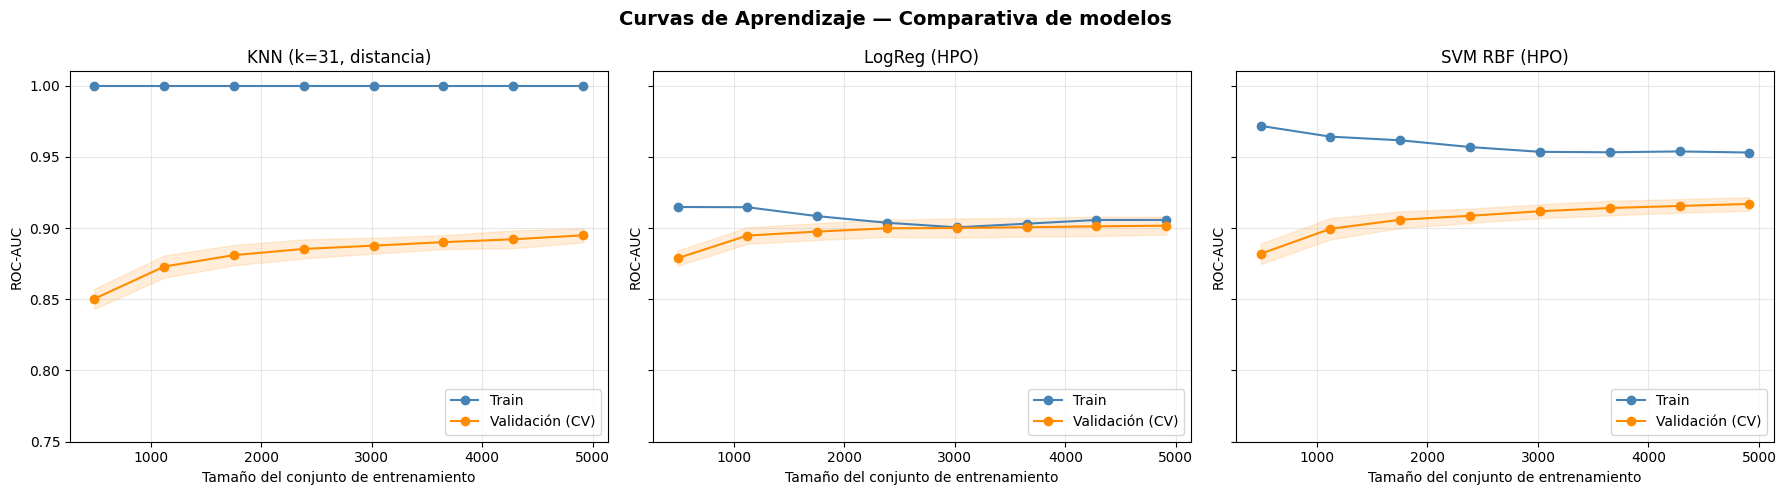

In [78]:
from sklearn.model_selection import learning_curve
import numpy as np
import matplotlib.pyplot as plt

# Calculamos las curvas de aprendizaje para los tres mejores modelos
modelos_lc = {
    'KNN (k=31, distancia)': grid_knn.best_estimator_,
    'LogReg (HPO)':          gs_lr.best_estimator_,
    'SVM RBF (HPO)':         gs_svm.best_estimator_,
}

train_sizes_pct = np.linspace(0.1, 1.0, 8)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, (nombre, modelo) in zip(axes, modelos_lc.items()):
    train_sizes, train_scores, val_scores = learning_curve(
        modelo, x_train, y_train,
        train_sizes=train_sizes_pct,
        cv=inner_cv,
        scoring='roc_auc',
        n_jobs=-1
    )
    train_mean = train_scores.mean(axis=1)
    val_mean   = val_scores.mean(axis=1)
    val_std    = val_scores.std(axis=1)

# Grafo de las curvas de aprendizaje
    ax.plot(train_sizes, train_mean, 'o-', color='steelblue', label='Train')
    ax.plot(train_sizes, val_mean,   'o-', color='darkorange', label='Validación (CV)')
    ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15, color='darkorange')
    ax.set_title(nombre)
    ax.set_xlabel('Tamaño del conjunto de entrenamiento')
    ax.set_ylabel('ROC-AUC')
    ax.legend(loc='lower right')
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0.75, 1.01)

plt.suptitle('Curvas de Aprendizaje — Comparativa de modelos', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Análisis de las curvas de aprendizaje

KNN: Presenta una diferencia notable entre train y validación con pocos datos, que se reduce progresivamente. Con el conjunto completo las curvas convergen, indicando que el modelo aprovecha bien los datos disponibles pero necesita un volumen considerable para generalizarse.

Regresión Logística: Las curvas train y validación convergen rápidamente con pocos datos y permanecen muy próximas. Esto evidencia que el modelo es estable y no sufre overfitting. Aporta rendimiento sólido ya con el 30-40% de los datos de entrenamiento.

SVM RBF: Muestra la mayor separación inicial entre train y validación, típica de modelos más complejos. Sin embargo, la curva de validación sigue subiendo con más datos y no se estabiliza completamente, lo que sugiere que el SVM podría beneficiarse de más datos si estuviesen disponibles a diferencia de LR, que ya ha alcanzado su techo con el conjunto actual.

Conclusión: Con el tamaño de datos disponible el SVM es el mejor modelo, pero si el banco dispusiese de más registros históricos, el SVM sería el que más mejoraría su rendimiento.

---

# **Uso de la IA Generativa**

Durante el desarrollo de esta práctica, se ha utilizado IA Generativa como ayuda a la hora de programar. Su uso se ha centrado en el debugging, la comprensión de conceptos, y la generación de gráficos para hacer las explicaciones más representativas.